# MBTI Student Compatibility Network

Exploratory notebook for our Graph Analytics project. Starting from the 16Personalities survey filled out by classmates, we use the 5 continuous trait scores (`Energy`, `Mind`, `Nature`, `Tactics`, `Identity`) to model student compatibility as a weighted network.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

raw = pd.read_csv("mbti_profiles.csv")

rename_cols = {
    "ID mail": "student",
    "MBTI": "mbti",
    "Variante": "variant",
    "Énergie · E (%)": "E",
    "Esprit · N (%)": "N",
    "Nature · T (%)": "T",
    "Tactique · J (%)": "J",
    "Identité · A (%)": "A",
}
traits = ["E", "N", "T", "J", "A"]

df = raw[raw["Complétion"] == "Yes"][list(rename_cols.keys())].rename(columns=rename_cols).copy()
for col in traits:
    df[col] = df[col].str.replace("%", "", regex=False).str.strip().astype(float) / 100.0

df = df.dropna(subset=traits + ["mbti"]).set_index("student")

mbti_types = sorted(df["mbti"].unique())
palette = plt.get_cmap("tab20")
type_colors = {t: palette(i) for i, t in enumerate(mbti_types)}

G_base = nx.Graph()
for student, row in df.iterrows():
    G_base.add_node(
        student,
        mbti=row["mbti"],
        variant=row["variant"],
        E=float(row["E"]),
        N=float(row["N"]),
        T=float(row["T"]),
        J=float(row["J"]),
        A=float(row["A"]),
    )


def plot_network(G, pos, title, highlight_above=None):
    plt.figure(figsize=(11.5, 8.5))

    colors = [type_colors[G.nodes[n]["mbti"]] for n in G.nodes]
    sizes = [550 + 45 * G.degree(n) for n in G.nodes]
    labels = {n: f"{n}\n({G.nodes[n]['mbti']})" for n in G.nodes}

    if highlight_above is not None:
        regular = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] < highlight_above]
        strong = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] >= highlight_above]
        nx.draw_networkx_edges(G, pos, edgelist=regular, alpha=0.28, edge_color="#888888", width=1.2)
        nx.draw_networkx_edges(
            G, pos, edgelist=strong, alpha=0.75, edge_color="#1f4e79",
            width=[2.2 + (G[u][v]["weight"] - highlight_above) * 20 for u, v in strong],
        )
    else:
        widths = [0.8 + G[u][v]["weight"] * 2.5 for u, v in G.edges]
        nx.draw_networkx_edges(G, pos, alpha=0.32, edge_color="#666666", width=widths)

    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes, edgecolors="white", linewidths=1.5)
    nx.draw_networkx_labels(
        G, pos, labels=labels, font_size=7.5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.65, pad=0.8),
    )

    legend_handles = [
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=type_colors[t], label=t, markersize=8)
        for t in mbti_types
    ]
    plt.legend(handles=legend_handles, title="MBTI", loc="best", fontsize=8)
    plt.title(title, fontsize=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


print(f"Loaded {len(df)} complete student profiles.")
df.head(10)

Loaded 23 complete student profiles.


,mbti,variant,E,N,T,J,A
student,,,,,,,
aambos,ENFJ,-T,0.56,0.64,0.40,0.53,0.36
abarcelo,ENTJ,-A,1.00,0.63,0.86,0.78,0.99
aravas,ENTJ,-A,0.67,0.61,0.67,0.67,0.71
aspira,ESTJ,-T,0.51,0.46,0.64,0.81,0.33
bledoyen,ENTJ,-A,0.51,0.73,0.69,0.54,0.51
booi,ENTJ,-A,0.52,0.61,0.54,0.54,0.69
cdefosseux,ESFJ,-T,0.54,0.45,0.39,0.57,0.49
enatali,INFJ,-T,0.46,0.64,0.49,0.57,0.39
gbalou,ENTJ,-T,0.65,0.85,0.63,0.67,0.49


## 1. Baseline: Trait Similarity Graph

As a first baseline, we link any two students whose average difference across the 5 traits is at most 20 percentage points (`similarity >= 0.80`).

Similarity graph: 23 nodes, 140 edges (density = 0.55)


,Student A,MBTI A,Student B,MBTI B,Similarity (%)
0,aambos,ENFJ,enatali,INFJ,94.8
1,tgillot,ENFP,zaich,ENFP,94.6
2,aspira,ESTJ,lchapoton,ESTJ,93.0
3,aambos,ENFJ,cdefosseux,ESFJ,92.2
4,aravas,ENTJ,booi,ENTJ,91.4
5,aspira,ESTJ,kechang,ISFJ,91.0
6,bledoyen,ENTJ,booi,ENTJ,90.8
7,bledoyen,ENTJ,gbalou,ENTJ,90.6
8,mzapata,INTP,tfoussard,ENTP,90.6
9,aravas,ENTJ,rlevasseur,ENTJ,90.6


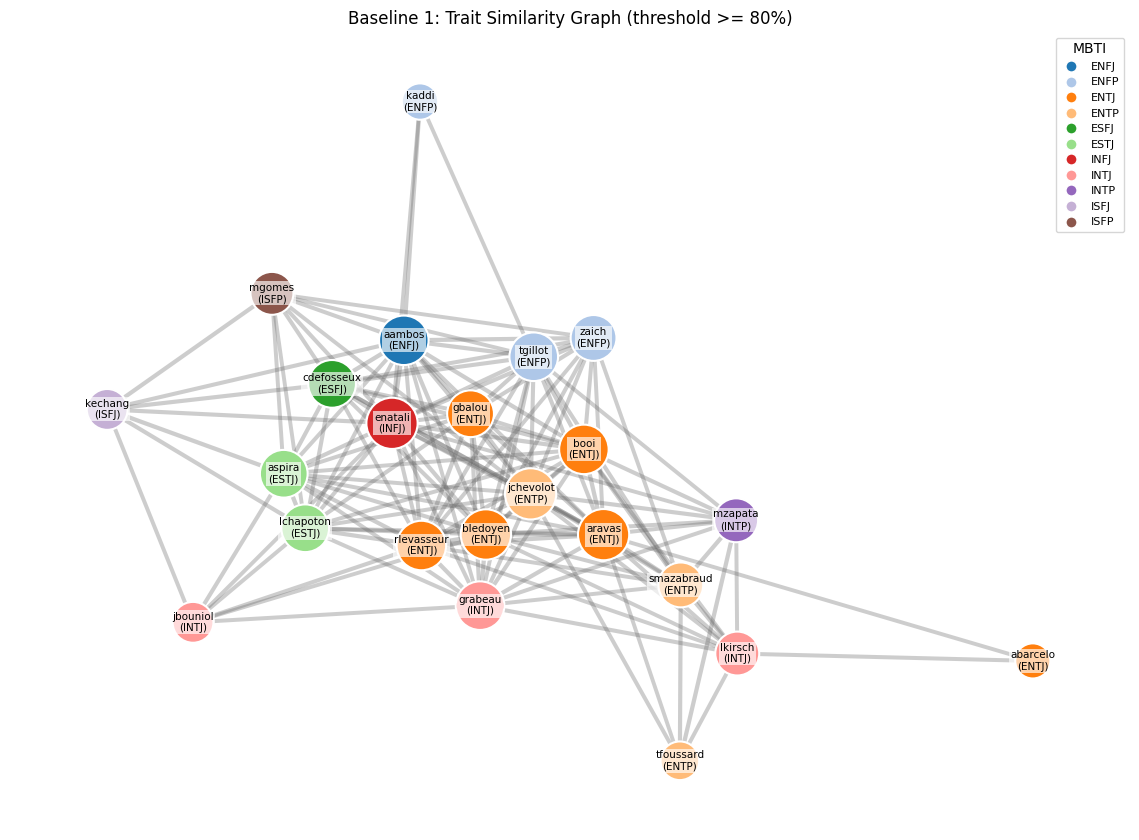

In [2]:
G_sim = G_base.copy()
students = df.index.tolist()
threshold = 0.80
sim_pairs = []

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        u, v = students[i], students[j]
        diff = np.abs(df.loc[u, traits].values - df.loc[v, traits].values)
        sim = float(1.0 - diff.mean())
        if sim >= threshold:
            G_sim.add_edge(u, v, weight=sim)
            sim_pairs.append({
                "Student A": u, "MBTI A": df.loc[u, "mbti"],
                "Student B": v, "MBTI B": df.loc[v, "mbti"],
                "Similarity (%)": round(sim * 100, 1),
            })

sim_df = pd.DataFrame(sim_pairs).sort_values("Similarity (%)", ascending=False).reset_index(drop=True)
print(f"Similarity graph: {G_sim.number_of_nodes()} nodes, {G_sim.number_of_edges()} edges (density = {nx.density(G_sim):.2f})")
display(sim_df.head(10))

pos_sim = nx.spring_layout(G_sim, seed=42, k=0.7, weight="weight")
plot_network(G_sim, pos_sim, "Baseline 1: Trait Similarity Graph (threshold >= 80%)")

## 2. Baseline: Trait Contrast Graph

Here we test the opposite intuition: connecting students who sit on opposite sides of the 50% mark on the 5 dimensions. We keep the top 5 most contrasting links per student.

Contrast graph: 23 nodes, 87 edges


,Student A,MBTI A,Student B,MBTI B,Contrast (%)
0,abarcelo,ENTJ,kaddi,ENFP,24.8
1,kaddi,ENFP,lkirsch,INTJ,23.0
2,kaddi,ENFP,tfoussard,ENTP,21.0
3,abarcelo,ENTJ,mgomes,ISFP,19.8
4,abarcelo,ENTJ,jbouniol,INTJ,15.9
5,kaddi,ENFP,smazabraud,ENTP,15.6
6,abarcelo,ENTJ,kechang,ISFJ,15.4
7,kechang,ISFJ,tfoussard,ENTP,15.2
8,kaddi,ENFP,mzapata,INTP,14.4
9,jbouniol,INTJ,tfoussard,ENTP,14.1


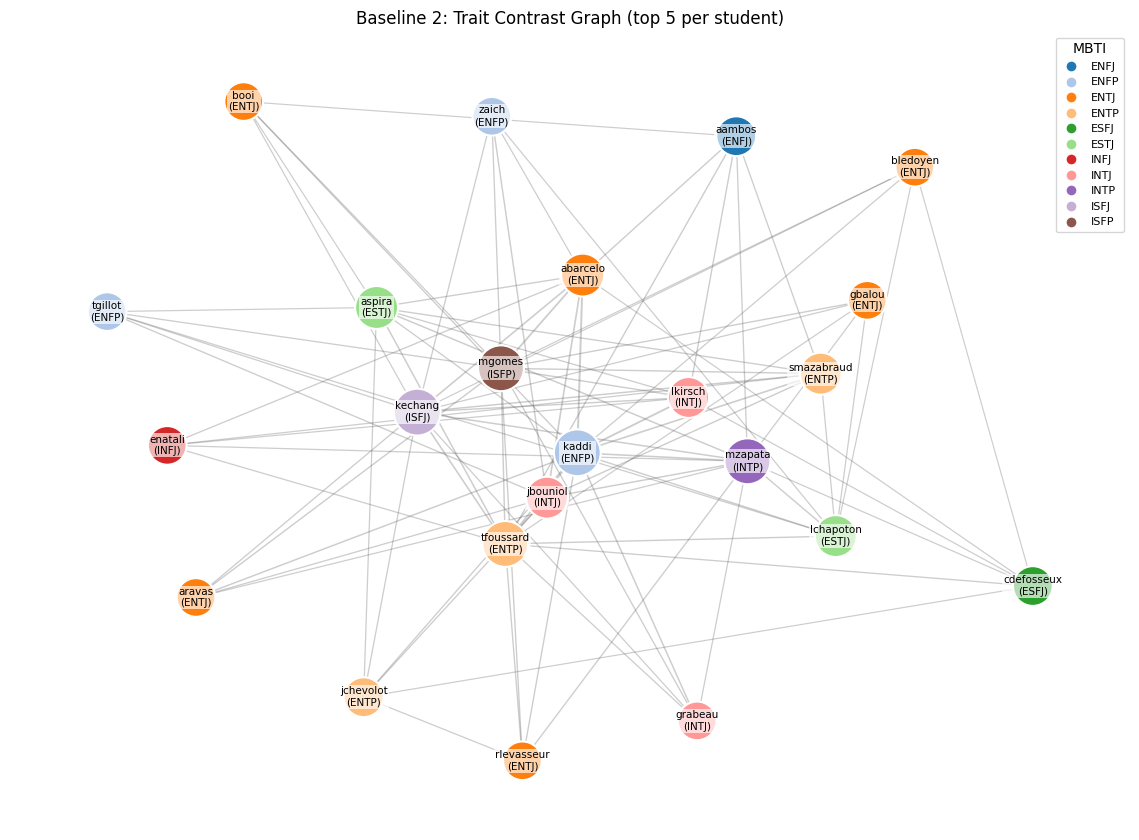

In [3]:
G_contrast = G_base.copy()
top_k = 5
centered = df[traits].values - 0.5
contrast_scores = {}

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        opposition = 4.0 * np.maximum(0.0, -(centered[i] * centered[j]))
        contrast_scores[(i, j)] = float(opposition.mean())

for i, u in enumerate(students):
    neighbors = [
        (students[j], contrast_scores[(min(i, j), max(i, j))])
        for j in range(len(students)) if i != j
    ]
    neighbors.sort(key=lambda x: x[1], reverse=True)
    for v, score in neighbors[:top_k]:
        G_contrast.add_edge(u, v, weight=score)

contrast_df = pd.DataFrame([
    {
        "Student A": u, "MBTI A": df.loc[u, "mbti"],
        "Student B": v, "MBTI B": df.loc[v, "mbti"],
        "Contrast (%)": round(d["weight"] * 100, 1),
    }
    for u, v, d in G_contrast.edges(data=True)
]).sort_values("Contrast (%)", ascending=False).reset_index(drop=True)

print(f"Contrast graph: {G_contrast.number_of_nodes()} nodes, {G_contrast.number_of_edges()} edges")
display(contrast_df.head(10))

pos_con = nx.spring_layout(G_contrast, seed=42, k=0.7)
plot_network(G_contrast, pos_con, f"Baseline 2: Trait Contrast Graph (top {top_k} per student)")

## 3. Work-Group Compatibility Graph

Pure similarity creates a very dense graph where almost everyone is linked, while pure opposition pairs profiles that may clash on organization and communication. 

To model realistic project teams, we define an ideal partner vector for each student across the 5 traits:
- **Energy (`E`)**: complementary (`1 - E`), balancing outspoken and quieter team members.
- **Mind (`N`) & Nature (`T`)**: aligned (`N`, `T`), so teammates process ideas and feedback in a compatible way.
- **Tactics (`J`) & Identity (`A`)**: averaged with `0.65` (`(x + 0.65) / 2`), slightly favoring structure and emotional steadiness under deadlines.

We average the normalized Euclidean distance in both directions to get a symmetric score, then build an undirected $k$-NN graph ($k = 4$).

Compatibility graph (4-NN): 23 nodes, 67 edges, density = 0.26, connected = True, degree range = [4, 10]


,Student A,Type A,Student B,Type B,Compatibility (%)
0,grabeau,INTJ-A,rlevasseur,ENTJ-A,93.8
1,aravas,ENTJ-A,grabeau,INTJ-A,92.5
2,aambos,ENFJ-T,enatali,INFJ-T,92.2
3,bledoyen,ENTJ-A,grabeau,INTJ-A,91.6
4,aspira,ESTJ-T,lchapoton,ESTJ-T,90.3
5,gbalou,ENTJ-T,grabeau,INTJ-A,89.3
6,booi,ENTJ-A,enatali,INFJ-T,89.2
7,bledoyen,ENTJ-A,booi,ENTJ-A,89.1
8,bledoyen,ENTJ-A,gbalou,ENTJ-T,89.1
9,cdefosseux,ESFJ-T,kechang,ISFJ-T,89.1


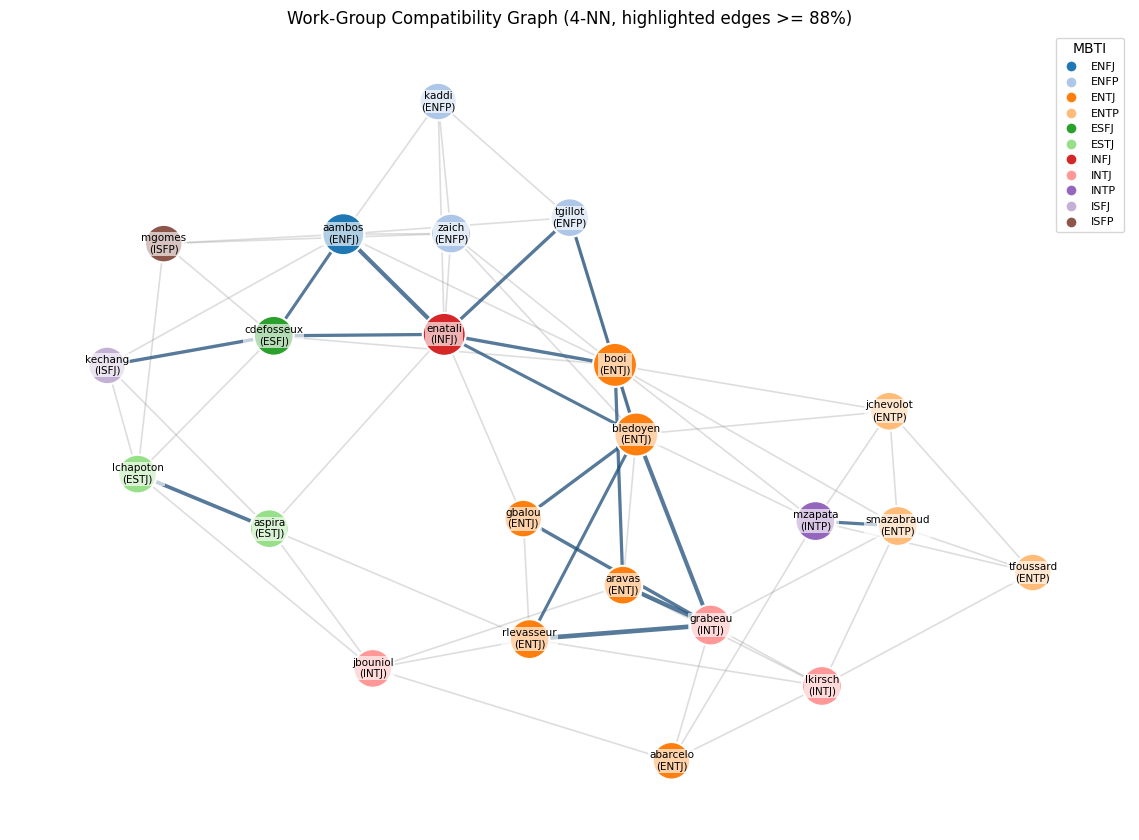

In [4]:
def ideal_partner(x, anchor=0.65):
    return np.array([
        1.0 - x[0],             # E: complementary energy
        x[1],                   # N: aligned intuition/sensing
        x[2],                   # T: aligned thinking/feeling
        0.5 * (x[3] + anchor),  # J: pulled toward structure
        0.5 * (x[4] + anchor),  # A: pulled toward calm stability
    ])


X = df[traits].values
X_ideal = np.array([ideal_partner(row) for row in X])
n = len(students)

compat_matrix = np.zeros((n, n))
compat_pairs = []

for i in range(n):
    for j in range(i + 1, n):
        u, v = students[i], students[j]
        d_ab = np.linalg.norm(X[j] - X_ideal[i]) / np.sqrt(len(traits))
        d_ba = np.linalg.norm(X[i] - X_ideal[j]) / np.sqrt(len(traits))
        score = float(1.0 - 0.5 * (d_ab + d_ba))

        compat_matrix[i, j] = compat_matrix[j, i] = score
        compat_pairs.append({
            "Student A": u, "Type A": f"{df.loc[u, 'mbti']}{df.loc[u, 'variant']}",
            "Student B": v, "Type B": f"{df.loc[v, 'mbti']}{df.loc[v, 'variant']}",
            "Compatibility (%)": round(score * 100, 1),
        })

G_compat = G_base.copy()
k_neighbors = 4
for i, u in enumerate(students):
    top_idx = [j for j in np.argsort(compat_matrix[i])[::-1] if j != i][:k_neighbors]
    for j in top_idx:
        G_compat.add_edge(u, students[j], weight=compat_matrix[i, j])

compat_df = pd.DataFrame(compat_pairs).sort_values("Compatibility (%)", ascending=False).reset_index(drop=True)
deg = dict(G_compat.degree())
print(
    f"Compatibility graph ({k_neighbors}-NN): {G_compat.number_of_nodes()} nodes, "
    f"{G_compat.number_of_edges()} edges, density = {nx.density(G_compat):.2f}, "
    f"connected = {nx.is_connected(G_compat)}, degree range = [{min(deg.values())}, {max(deg.values())}]"
)
display(compat_df.head(15))

pos_compat = nx.spring_layout(G_compat, seed=42, k=0.9, iterations=150, weight="weight")
plot_network(
    G_compat,
    pos_compat,
    f"Work-Group Compatibility Graph ({k_neighbors}-NN, highlighted edges >= 88%)",
    highlight_above=0.88,
)

## 4. Connectivity and Parameter Sensitivity

A graph is connected when every pair of students has a path between them. We first compare the three model graphs at their current settings, then vary the similarity cutoff, the number of contrast links retained per student, and the compatibility $k$-nearest-neighbor value. Every rebuilt graph keeps all students as nodes; for directed neighbor selections, an undirected edge is included if either student selects the other.

The component count and largest-component share show when a model fragments. Shortest-path distances between different components are undefined (effectively infinite), so a disconnected graph has no finite whole-graph diameter or radius. For later distance analysis, report metrics per component or explicitly restrict them to the largest component; for compatibility-weighted distances, use edge cost $d = 1 - w$ rather than treating compatibility itself as a distance.

In [5]:
def connectivity_summary(G, model, setting):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    largest_size = len(components[0]) if components else 0
    node_count = G.number_of_nodes()
    return {
        "Model": model,
        "Setting": setting,
        "Nodes": node_count,
        "Edges": G.number_of_edges(),
        "Density": round(nx.density(G), 3),
        "Connected": len(components) == 1,
        "Components": len(components),
        "Largest component": largest_size,
        "Largest component (%)": round(100 * largest_size / node_count, 1) if node_count else 0.0,
        "Isolates": nx.number_of_isolates(G),
        "Component sizes": [len(component) for component in components],
    }


baseline_connectivity = pd.DataFrame([
    connectivity_summary(G_sim, "Trait similarity", f"threshold >= {threshold:.2f}"),
    connectivity_summary(G_contrast, "Trait contrast", f"top {top_k} per student"),
    connectivity_summary(G_compat, "Compatibility", f"{k_neighbors}-NN"),
])
display(baseline_connectivity)

similarity_sweep = []
for cutoff in np.round(np.arange(0.60, 0.951, 0.05), 2):
    graph = G_base.copy()
    for i in range(len(students)):
        for j in range(i + 1, len(students)):
            similarity = float(1.0 - np.abs(df.loc[students[i], traits].values - df.loc[students[j], traits].values).mean())
            if similarity >= cutoff:
                graph.add_edge(students[i], students[j], weight=similarity)
    similarity_sweep.append(connectivity_summary(graph, "Trait similarity", f"threshold >= {cutoff:.2f}"))

contrast_sweep = []
compatibility_sweep = []
for k in range(1, len(students)):
    contrast_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            ((j, contrast_scores[(min(i, j), max(i, j))]) for j in range(len(students)) if j != i),
            key=lambda item: item[1],
            reverse=True,
        )
        for j, score in ranked[:k]:
            contrast_graph.add_edge(student, students[j], weight=score)
    contrast_sweep.append(connectivity_summary(contrast_graph, "Trait contrast", f"top {k} per student"))

    compatibility_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            (j for j in range(len(students)) if j != i),
            key=lambda j: compat_matrix[i, j],
            reverse=True,
        )
        for j in ranked[:k]:
            compatibility_graph.add_edge(student, students[j], weight=compat_matrix[i, j])
    compatibility_sweep.append(connectivity_summary(compatibility_graph, "Compatibility", f"{k}-NN"))

sweep_columns = ["Setting", "Edges", "Density", "Connected", "Components", "Largest component", "Largest component (%)", "Isolates"]
display(pd.DataFrame(similarity_sweep)[sweep_columns])
display(pd.DataFrame(contrast_sweep)[sweep_columns])
display(pd.DataFrame(compatibility_sweep)[sweep_columns])

,Model,Setting,Nodes,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates,Component sizes
0,Trait similarity,threshold >= 0.80,23,140,0.553,True,1,23,100.0,0,[23]
1,Trait contrast,top 5 per student,23,87,0.344,True,1,23,100.0,0,[23]
2,Compatibility,4-NN,23,67,0.265,True,1,23,100.0,0,[23]


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,threshold >= 0.60,249,0.984,True,1,23,100.0,0
1,threshold >= 0.65,241,0.953,True,1,23,100.0,0
2,threshold >= 0.70,223,0.881,True,1,23,100.0,0
3,threshold >= 0.75,194,0.767,True,1,23,100.0,0
4,threshold >= 0.80,140,0.553,True,1,23,100.0,0
5,threshold >= 0.85,70,0.277,False,3,21,91.3,2
6,threshold >= 0.90,19,0.075,False,9,10,43.5,5
7,threshold >= 0.95,0,0.000,False,23,1,4.3,23


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,top 1 per student,22,0.087,True,1,23,100.0,0
1,top 2 per student,41,0.162,True,1,23,100.0,0
2,top 3 per student,59,0.233,True,1,23,100.0,0
3,top 4 per student,74,0.292,True,1,23,100.0,0
4,top 5 per student,87,0.344,True,1,23,100.0,0
5,top 6 per student,102,0.403,True,1,23,100.0,0
6,top 7 per student,112,0.443,True,1,23,100.0,0
7,top 8 per student,125,0.494,True,1,23,100.0,0
8,top 9 per student,135,0.534,True,1,23,100.0,0
9,top 10 per student,146,0.577,True,1,23,100.0,0


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,1-NN,18,0.071,False,5,9,39.1,0
1,2-NN,37,0.146,True,1,23,100.0,0
2,3-NN,52,0.206,True,1,23,100.0,0
3,4-NN,67,0.265,True,1,23,100.0,0
4,5-NN,81,0.320,True,1,23,100.0,0
5,6-NN,96,0.379,True,1,23,100.0,0
6,7-NN,111,0.439,True,1,23,100.0,0
7,8-NN,124,0.490,True,1,23,100.0,0
8,9-NN,136,0.538,True,1,23,100.0,0
9,10-NN,150,0.593,True,1,23,100.0,0


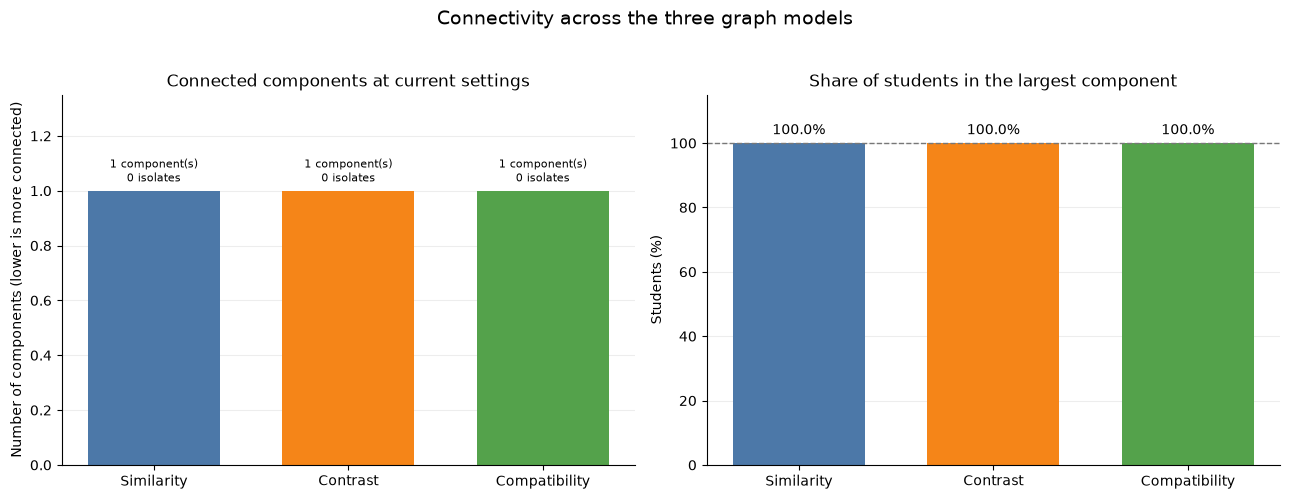

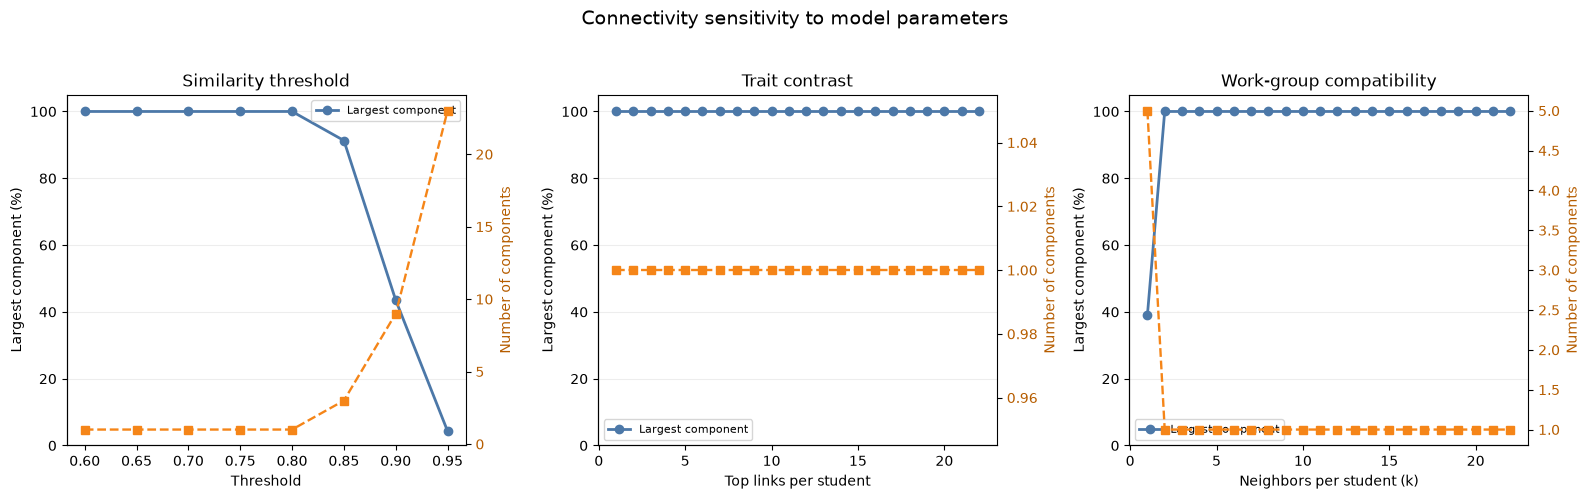

In [11]:
model_order = ["Trait similarity", "Trait contrast", "Work-group compatibility"]
model_colors = {
    "Trait similarity": "#4C78A8",
    "Trait contrast": "#F58518",
    "Work-group compatibility": "#54A24B",
}

# Compare the current graph settings by component structure and reachable share.
baseline_plot = baseline_connectivity.set_index("Model").rename(index={"Compatibility": "Work-group compatibility"}).reindex(model_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bar_colors = [model_colors[model] for model in model_order]

bars = axes[0].bar(
    ["Similarity", "Contrast", "Compatibility"],
    baseline_plot["Components"],
    color=bar_colors,
    width=0.68,
)
axes[0].set_title("Connected components at current settings")
axes[0].set_ylabel("Number of components (lower is more connected)")
axes[0].bar_label(
    bars,
    labels=[
        f"{int(row['Components'])} component(s)\n{int(row['Isolates'])} isolates"
        for _, row in baseline_plot.iterrows()
    ],
    padding=4,
    fontsize=8,
)
axes[0].set_ylim(0, max(1, baseline_plot["Components"].max()) * 1.35)

bars = axes[1].bar(
    ["Similarity", "Contrast", "Compatibility"],
    baseline_plot["Largest component (%)"],
    color=bar_colors,
    width=0.68,
)
axes[1].set_title("Share of students in the largest component")
axes[1].set_ylabel("Students (%)")
axes[1].set_ylim(0, 115)
axes[1].bar_label(bars, fmt="%.1f%%", padding=4)
axes[1].axhline(100, color="#777777", linestyle="--", linewidth=1)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
fig.suptitle("Connectivity across the three graph models", fontsize=14, y=1.03)
fig.tight_layout()
plt.show()

# Show how the largest component and total component count change as each model is tuned.
sweep_specs = [
    (similarity_sweep, "Similarity threshold", "Threshold"),
    (contrast_sweep, "Trait contrast", "Top links per student"),
    (compatibility_sweep, "Work-group compatibility", "Neighbors per student (k)"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (sweep, title, x_label) in zip(axes, sweep_specs):
    sweep_plot = pd.DataFrame(sweep).copy()
    sweep_plot["Parameter"] = sweep_plot["Setting"].str.extract(r"([0-9]+(?:\.[0-9]+)?)").astype(float)
    sweep_plot = sweep_plot.sort_values("Parameter")
    x = sweep_plot["Parameter"]
    ax.plot(
        x,
        sweep_plot["Largest component (%)"],
        color="#4C78A8",
        marker="o",
        linewidth=2,
        label="Largest component",
    )
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel("Largest component (%)")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)

    component_axis = ax.twinx()
    component_axis.plot(
        x,
        sweep_plot["Components"],
        color="#F58518",
        marker="s",
        linestyle="--",
        linewidth=1.7,
        label="Component count",
    )
    component_axis.set_ylabel("Number of components", color="#B65D00")
    component_axis.tick_params(axis="y", labelcolor="#B65D00")
    ax.legend(loc="best", fontsize=8)
fig.suptitle("Connectivity sensitivity to model parameters", fontsize=14, y=1.03)
fig.tight_layout()
plt.show()


## 5. Distance Measures

Distance measures summarize how many steps, or how much cumulative edge cost, separates students in each graph. The **unweighted diameter** is the longest shortest-path distance in hops; the **unweighted radius** is the smallest, over students, of their farthest hop distance. These show worst-case reach and how centrally located the best-positioned student is.

For weighted distances, the edge `weight` represents tie strength, not cost. Convert each weight `w` to a cost `d = 1 - w`, then sum costs along a path and choose the least-cost path. This makes stronger ties cheaper to traverse. It is a modeling assumption for all three graphs; in particular, the contrast graph's strength means degree of contrast, not trait similarity.

A disconnected graph has no path between components, so its whole-graph diameter and radius are undefined. We report both metrics separately for every connected component; a singleton component therefore has diameter and radius 0. Comparisons across component rows should account for their different sizes.

In [8]:
def distance_metrics_by_component(G, model):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    rows = []

    for component_number, nodes in enumerate(components, start=1):
        component = G.subgraph(nodes).copy()
        weighted_component = component.copy()

        for _, _, attrs in weighted_component.edges(data=True):
            if "weight" not in attrs:
                raise ValueError(f"{model} has an edge without a strength weight")
            strength = float(attrs["weight"])
            if not np.isfinite(strength) or not 0.0 <= strength <= 1.0:
                raise ValueError(f"{model} edge strengths must be finite values in [0, 1]")
            attrs["distance"] = 1.0 - strength

        weighted_shortest_paths = dict(
            nx.all_pairs_dijkstra_path_length(weighted_component, weight="distance")
        )
        weighted_eccentricities = {
            node: max(distances.values())
            for node, distances in weighted_shortest_paths.items()
        }

        rows.append({
            "Model": model,
            "Graph connected": len(components) == 1,
            "Component": component_number,
            "Component nodes": component.number_of_nodes(),
            "Component edges": component.number_of_edges(),
            "Diameter (hops)": nx.diameter(component),
            "Radius (hops)": nx.radius(component),
            "Weighted diameter (sum of 1 - w)": round(max(weighted_eccentricities.values()), 3),
            "Weighted radius (sum of 1 - w)": round(min(weighted_eccentricities.values()), 3),
        })

    return rows


distance_results = pd.DataFrame([
    row
    for model, graph in [
        ("Trait similarity", G_sim),
        ("Trait contrast", G_contrast),
        ("Work-group compatibility", G_compat),
    ]
    for row in distance_metrics_by_component(graph, model)
])
display(distance_results)

,Model,Graph connected,Component,Component nodes,Component edges,Diameter (hops),Radius (hops),Weighted diameter (sum of 1 - w),Weighted radius (sum of 1 - w)
0,Trait similarity,True,1,23,140,3,2,0.522,0.278
1,Trait contrast,True,1,23,87,3,2,2.705,1.746
2,Work-group compatibility,True,1,23,67,4,2,0.644,0.358


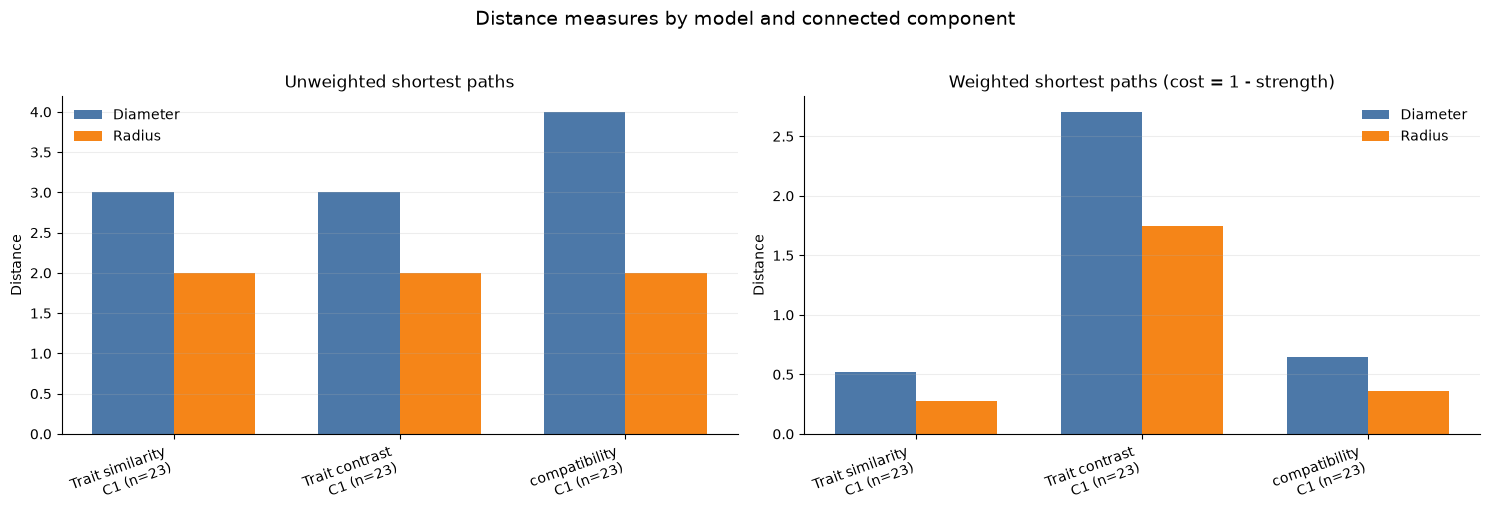

In [12]:
# Compare hop distances and strength-derived costs for every connected component.
distance_plot = distance_results.copy()
distance_plot["Component label"] = distance_plot.apply(
    lambda row: f"{row['Model'].replace('Work-group ', '')}\nC{int(row['Component'])} (n={int(row['Component nodes'])})",
    axis=1,
)
distance_x = np.arange(len(distance_plot))
bar_width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
distance_specs = [
    ("Diameter (hops)", "Radius (hops)", "Unweighted shortest paths"),
    ("Weighted diameter (sum of 1 - w)", "Weighted radius (sum of 1 - w)", "Weighted shortest paths (cost = 1 - strength)"),
]
for ax, (diameter_col, radius_col, title) in zip(axes, distance_specs):
    ax.bar(distance_x - bar_width / 2, distance_plot[diameter_col], bar_width, label="Diameter", color="#4C78A8")
    ax.bar(distance_x + bar_width / 2, distance_plot[radius_col], bar_width, label="Radius", color="#F58518")
    ax.set_title(title)
    ax.set_ylabel("Distance")
    ax.set_xticks(distance_x, distance_plot["Component label"], rotation=20, ha="right")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distance measures by model and connected component", fontsize=14, y=1.03)
fig.tight_layout()
plt.show()


## 6. Centrality Measures

Centrality describes a student's structural position in the network, not their personality or real-world importance. We compute each measure for all three graph models so that their different notions of a tie (similarity, contrast, or work compatibility) can be examined separately. Interpret values across models with those different edge meanings in mind.

- **Degree** counts immediate connections; **degree centrality** normalizes that count by graph size. In the symmetrized k-nearest-neighbor graph, a student may have more than `k` neighbors because other students can select them.
- **Strength** sums incident edge weights. It distinguishes many links from strong links, and its meaning follows each model's definition of edge weight.
- **Betweenness** measures how often a student lies on shortest paths between others. We use unweighted (hop-based) paths to identify topological bridges without inventing a conversion from tie strength to distance.
- **Closeness** summarizes hop distance to reachable students. NetworkX's Wasserman-Faust adjustment reduces scores for students who can reach only a small component, so disconnected graphs are handled explicitly.
- **Eigenvector centrality** rewards links to well-connected students. We calculate it separately within each connected component (using edge strength), since scores from different components are not directly comparable. A singleton component receives a score of 1 by convention.

The full table shows scores in each model; the final table highlights the five highest scores per measure in the work-group compatibility graph. Student identifiers match those used in the earlier tables.

In [10]:
graph_models = [
    ("Trait similarity", G_sim),
    ("Trait contrast", G_contrast),
    ("Work-group compatibility", G_compat),
]
centrality_rows = []
for model, graph in graph_models:
    degree = dict(graph.degree())
    degree_centrality = nx.degree_centrality(graph)
    strength = dict(graph.degree(weight="weight"))
    betweenness = nx.betweenness_centrality(graph, normalized=True)
    closeness = nx.closeness_centrality(graph, wf_improved=True)

    eigenvector = {}
    component_numbers = {}
    components = sorted(nx.connected_components(graph), key=len, reverse=True)
    for component_number, nodes in enumerate(components, start=1):
        component_graph = graph.subgraph(nodes)
        component_numbers.update({node: component_number for node in nodes})
        if len(nodes) == 1:
            eigenvector.update({node: 1.0 for node in nodes})
        else:
            eigenvector.update(nx.eigenvector_centrality(component_graph, max_iter=1000, weight="weight"))

    for node in graph:
        centrality_rows.append({
            "Model": model,
            "Student": node,
            "MBTI": f"{df.loc[node, 'mbti']}{df.loc[node, 'variant']}",
            "Component": component_numbers[node],
            "Degree": degree[node],
            "Degree centrality": degree_centrality[node],
            "Strength": strength[node],
            "Betweenness": betweenness[node],
            "Closeness": closeness[node],
            "Eigenvector": eigenvector[node],
        })

centrality_results = pd.DataFrame(centrality_rows)
display(centrality_results.sort_values(["Model", "Betweenness"], ascending=[True, False]).reset_index(drop=True))

compatibility_centrality = centrality_results[
    centrality_results["Model"] == "Work-group compatibility"
]
top_centrality_rows = []
for measure in ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]:
    top_rows = compatibility_centrality.nlargest(5, measure)[["Student", "MBTI", measure]].rename(
        columns={measure: "Score"}
    )
    top_rows.insert(0, "Measure", measure)
    top_centrality_rows.append(top_rows)
top_compatibility_centrality = pd.concat(top_centrality_rows, ignore_index=True)
display(top_compatibility_centrality)

,Model,Student,MBTI,Component,Degree,Degree centrality,Strength,Betweenness,Closeness,Eigenvector
0,Trait contrast,kechang,ISFJ-T,1,13,0.590909,1.000640,0.105786,0.709677,0.273887
1,Trait contrast,mgomes,ISFP-T,1,12,0.545455,0.992080,0.098747,0.687500,0.247980
2,Trait contrast,kaddi,ENFP-T,1,13,0.590909,1.627840,0.096482,0.709677,0.460342
3,Trait contrast,mzapata,INTP-A,1,12,0.545455,0.924160,0.092829,0.687500,0.252537
4,Trait contrast,tfoussard,ENTP-A,1,12,0.545455,1.173680,0.079465,0.687500,0.342124
...,...,...,...,...,...,...,...,...,...,...
64,Work-group compatibility,mgomes,ISFP-T,1,4,0.181818,3.346564,0.011224,0.423077,0.124333
65,Work-group compatibility,gbalou,ENTJ-T,1,4,0.181818,3.485501,0.011018,0.500000,0.169677
66,Work-group compatibility,kechang,ISFJ-T,1,4,0.181818,3.477962,0.009173,0.431373,0.111351
67,Work-group compatibility,tfoussard,ENTP-A,1,4,0.181818,3.266018,0.003608,0.392857,0.104570


,Measure,Student,MBTI,Score
0,Degree,bledoyen,ENTJ-A,10.000000
1,Degree,booi,ENTJ-A,10.000000
2,Degree,enatali,INFJ-T,9.000000
3,Degree,aambos,ENFJ-T,8.000000
4,Degree,grabeau,INTJ-A,7.000000
5,Strength,bledoyen,ENTJ-A,8.747916
6,Strength,booi,ENTJ-A,8.703839
7,Strength,enatali,INFJ-T,7.845882
8,Strength,aambos,ENFJ-T,6.847955
9,Strength,grabeau,INTJ-A,6.140595


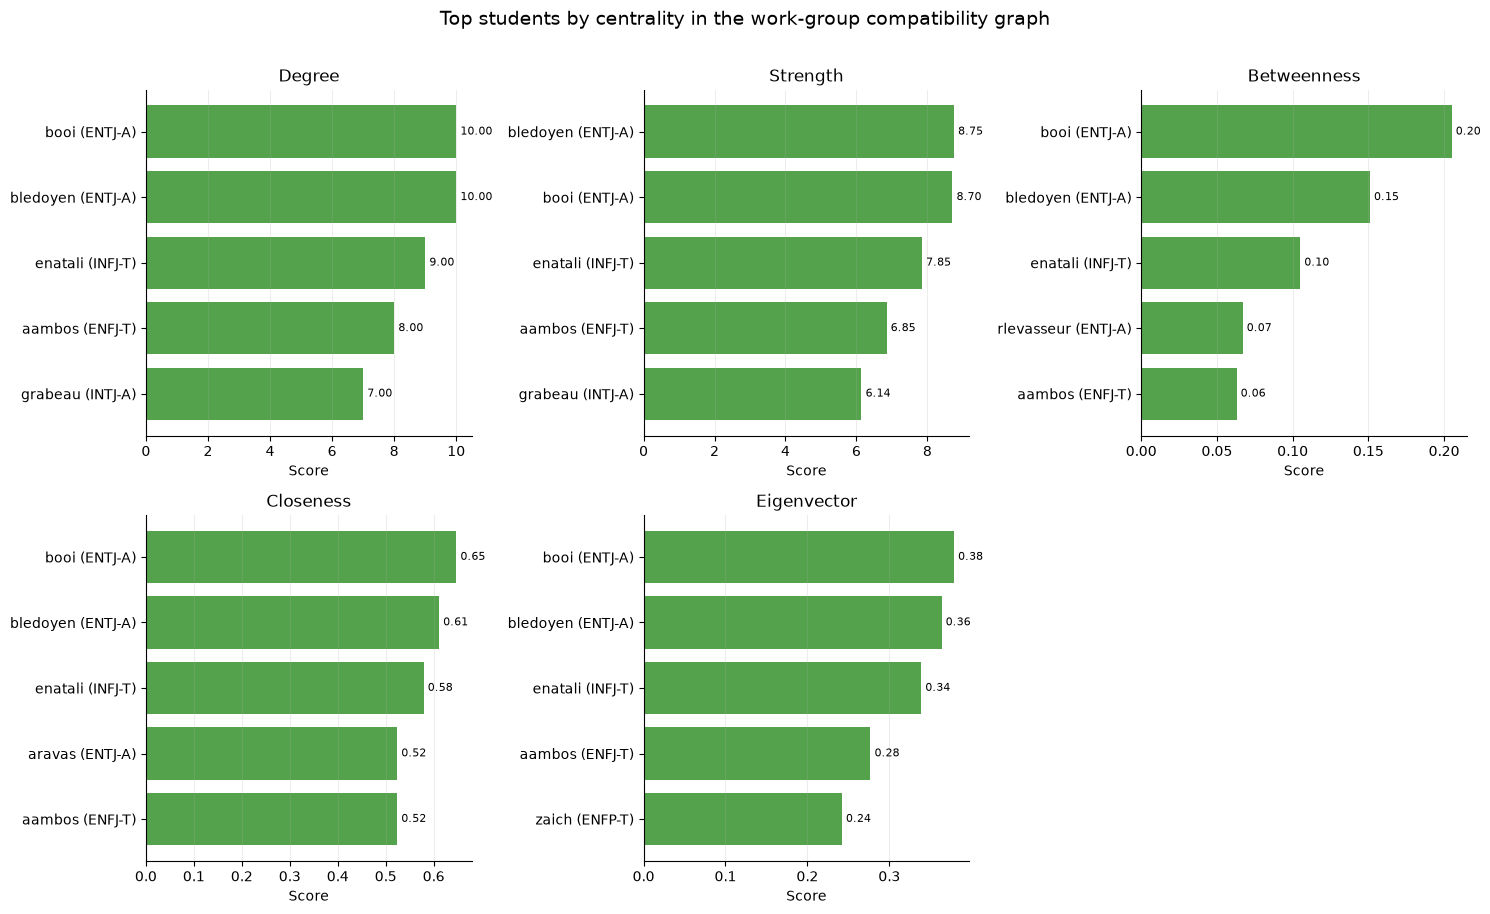

In [13]:
# Each centrality measure gets its own panel and scale; labels include MBTI type.
centrality_measures = ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, measure in zip(axes.flat, centrality_measures):
    top_students = compatibility_centrality.nlargest(5, measure).sort_values(measure)
    labels = [f"{row.Student} ({row.MBTI})" for row in top_students.itertuples()]
    bars = ax.barh(labels, top_students[measure], color="#54A24B")
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_title(measure)
    ax.set_xlabel("Score")
    ax.grid(axis="x", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[-1].set_visible(False)
fig.suptitle("Top students by centrality in the work-group compatibility graph", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()


## 7. Interactive HTML Graph

Export `G_compat` to an interactive HTML view (`graph.html`) using PyVis to explore local neighborhoods.

In [5]:
from pyvis.network import Network

net = Network(height="750px", width="100%", bgcolor="#ffffff", font_color="#222222", cdn_resources="in_line")
net.barnes_hut(gravity=-3500, central_gravity=0.3, spring_length=140)

for node, attrs in G_compat.nodes(data=True):
    tooltip = (
        f"{node} ({attrs['mbti']}{attrs['variant']})\n"
        f"E: {attrs['E']:.0%} | N: {attrs['N']:.0%} | T: {attrs['T']:.0%} | "
        f"J: {attrs['J']:.0%} | A: {attrs['A']:.0%}"
    )
    net.add_node(node, label=f"{node} ({attrs['mbti']})", title=tooltip, size=14 + 2 * G_compat.degree(node))

for u, v, attrs in G_compat.edges(data=True):
    w = attrs["weight"]
    net.add_edge(u, v, value=w, title=f"Compatibility: {w:.1%}")

net.write_html("graph.html", open_browser=False)
print("Saved interactive graph to graph.html")

Saved interactive graph to graph.html
